# Africa Economic, Banking & Systematic Crisis Data - Visualization Study

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing

In [ ]:
# Load our data
data = pd.read_csv("/content/african_crises.csv")
data.head()

,case,cc3,country,year,systemic_crisis,exch_usd,domestic_debt_in_default,sovereign_external_debt_default,gdp_weighted_default,inflation_annual_cpi,independence,currency_crises,inflation_crises,banking_crisis
0,1,DZA,Algeria,1870,1,0.052264,0,0,0.0,3.441456,0,0,0,crisis
1,1,DZA,Algeria,1871,0,0.052798,0,0,0.0,14.149140,0,0,0,no_crisis
2,1,DZA,Algeria,1872,0,0.052274,0,0,0.0,-3.718593,0,0,0,no_crisis
3,1,DZA,Algeria,1873,0,0.051680,0,0,0.0,11.203897,0,0,0,no_crisis
4,1,DZA,Algeria,1874,0,0.051308,0,0,0.0,-3.848561,0,0,0,no_crisis


In [ ]:
# How many countries are in this dataset
unique_countries=data.country.unique()
unique_countries

array(['Algeria', 'Angola', 'Central African Republic', 'Ivory Coast',
       'Egypt', 'Kenya', 'Mauritius', 'Morocco', 'Nigeria',
       'South Africa', 'Tunisia', 'Zambia', 'Zimbabwe'], dtype=object)

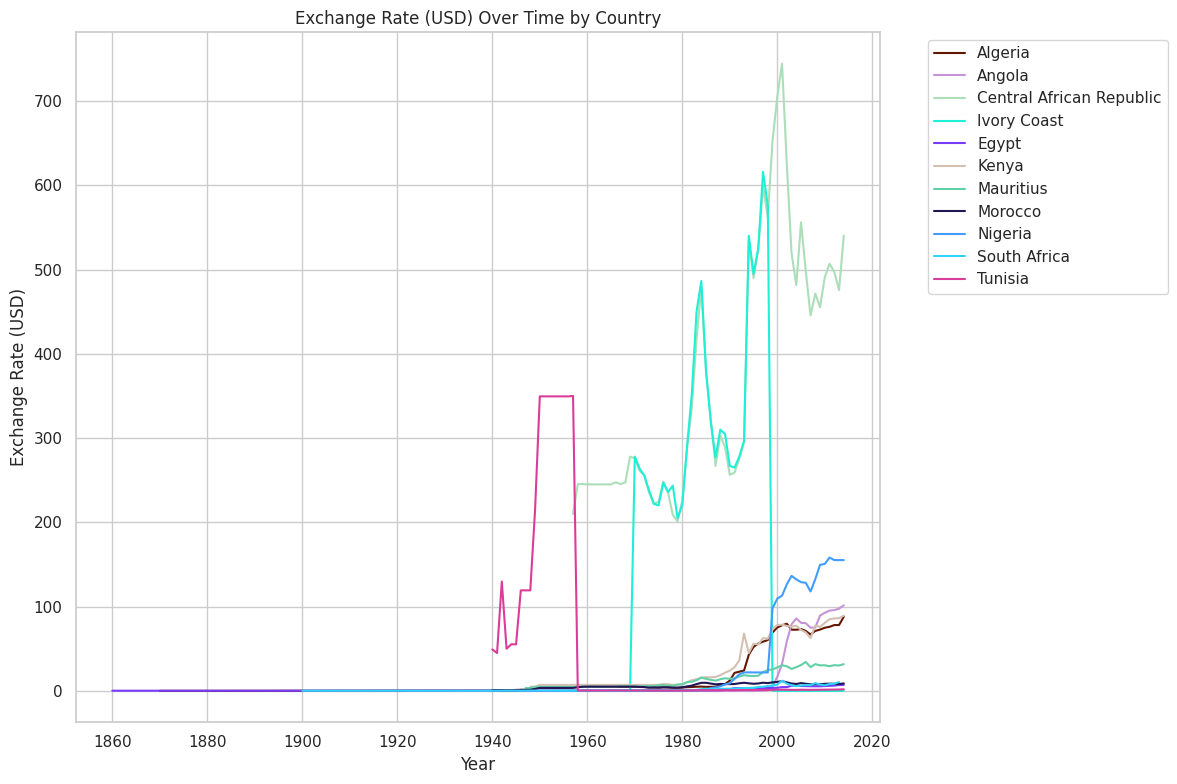

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import random

# Assuming 'data' is your DataFrame with columns: 'country', 'year', 'exch_usd'

# Method 1: Individual country plotting with random colors
plt.figure(figsize=(12, 8))
count = 0
for country in data['country'].unique():
    if count > 10:  # Limit to 10 countries for better readability
        break
    count += 1
    col = "#" + ''.join([random.choice('0123456789ABCDEF') for j in range(6)])

    # Corrected lineplot with keyword arguments
    sns.lineplot(
        x=data[data.country==country]['year'],
        y=data[data.country==country]['exch_usd'],
        label=country,
        color=col
    )

plt.title('Exchange Rate (USD) Over Time by Country')
plt.xlabel('Year')
plt.ylabel('Exchange Rate (USD)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# Year wise average usd exchange rate of each country

# Different debt count of each country

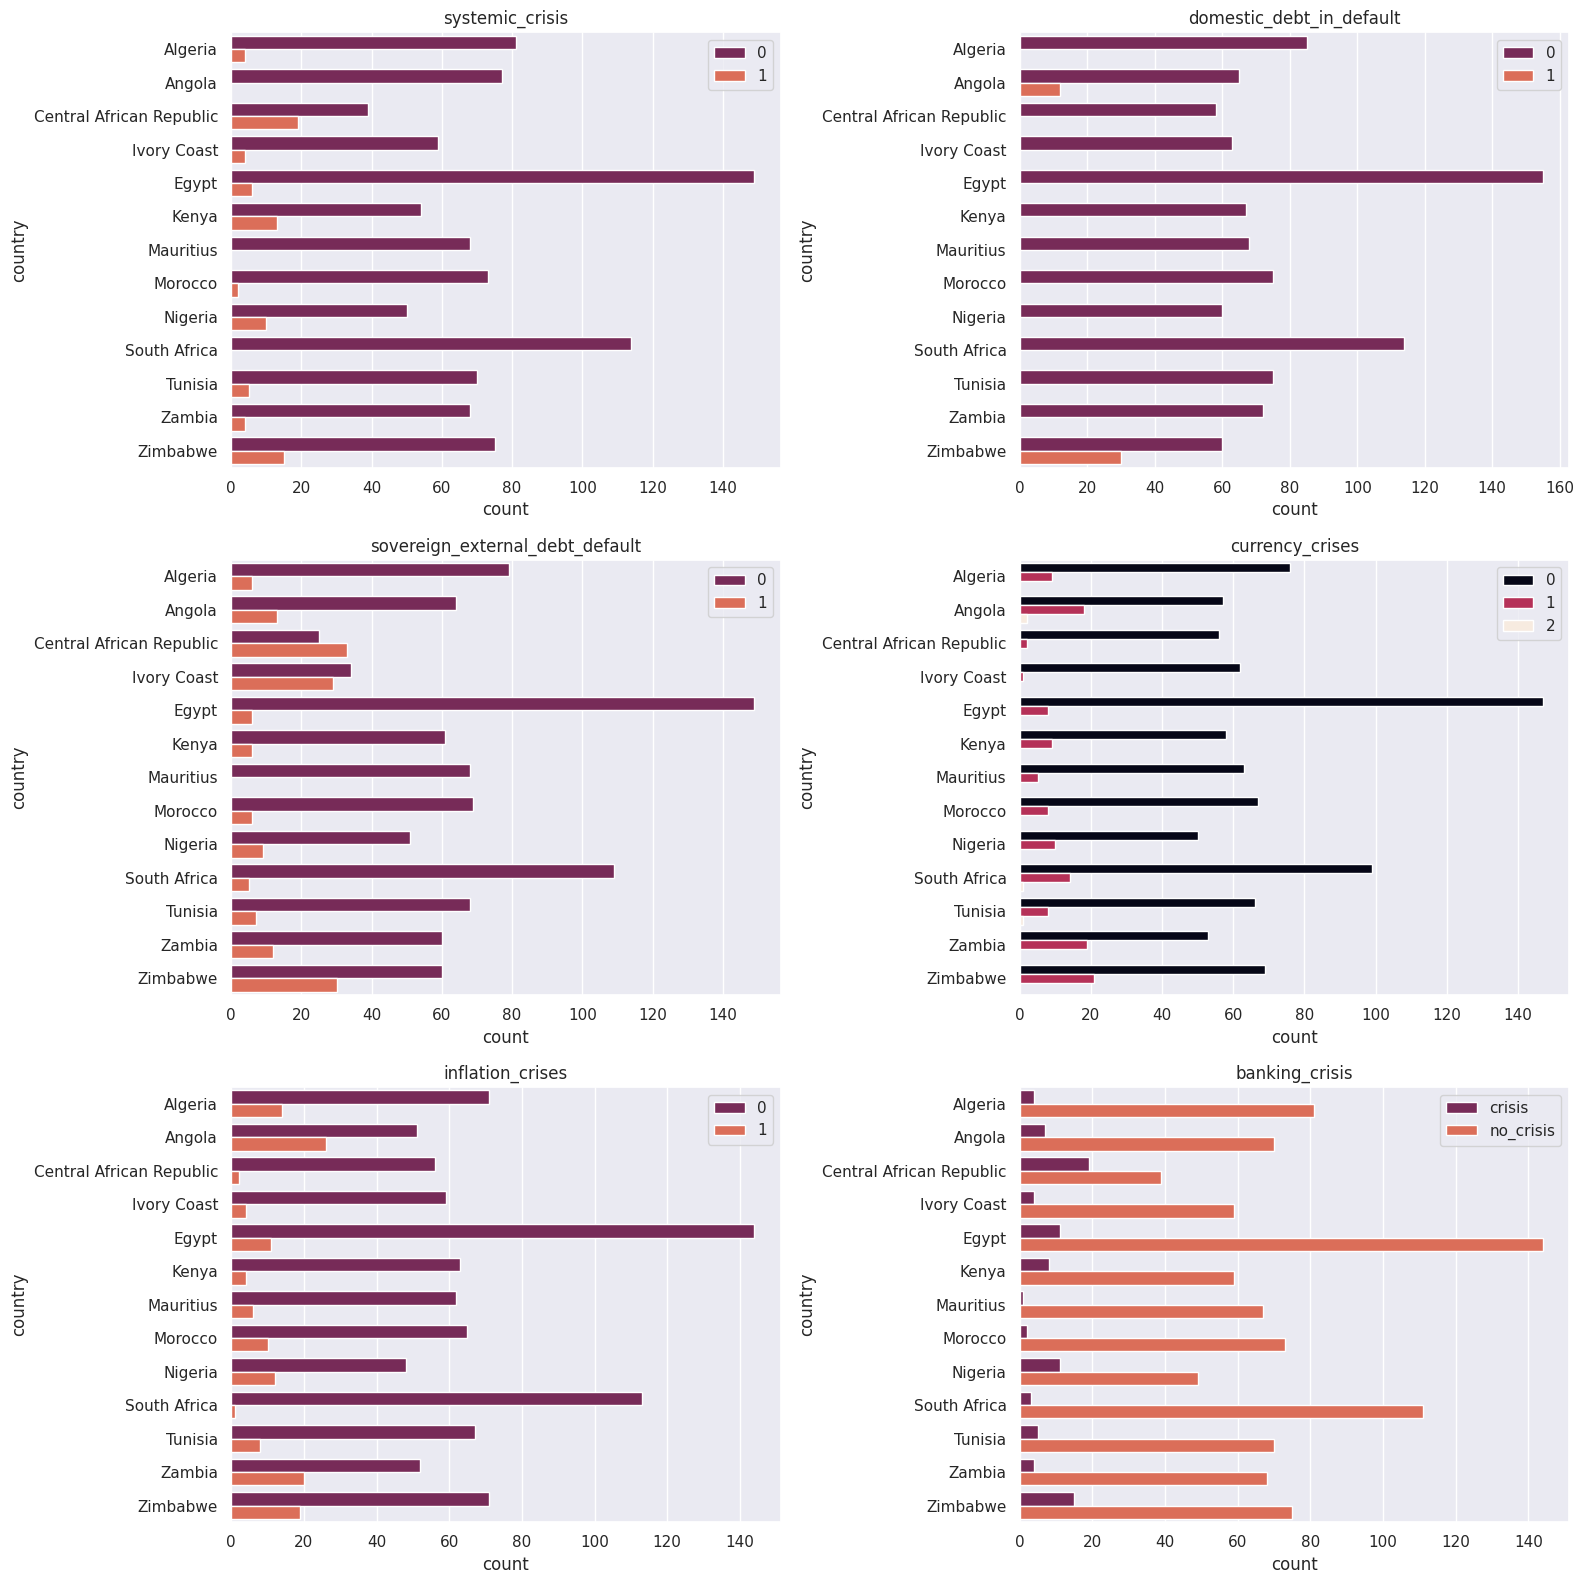

In [ ]:
sns.set(style='darkgrid')
cols=['systemic_crisis','domestic_debt_in_default','sovereign_external_debt_default','currency_crises','inflation_crises','banking_crisis']
plt.figure(figsize=(16,16))
count=1
for col in cols:
    plt.subplot(3,2,count)
    count+=1
    sns.countplot(y=data.country,hue=data[col],palette='rocket')
    plt.legend(loc=0)
    plt.title(col)
plt.tight_layout()
plt.show()

# Average year wise inflation

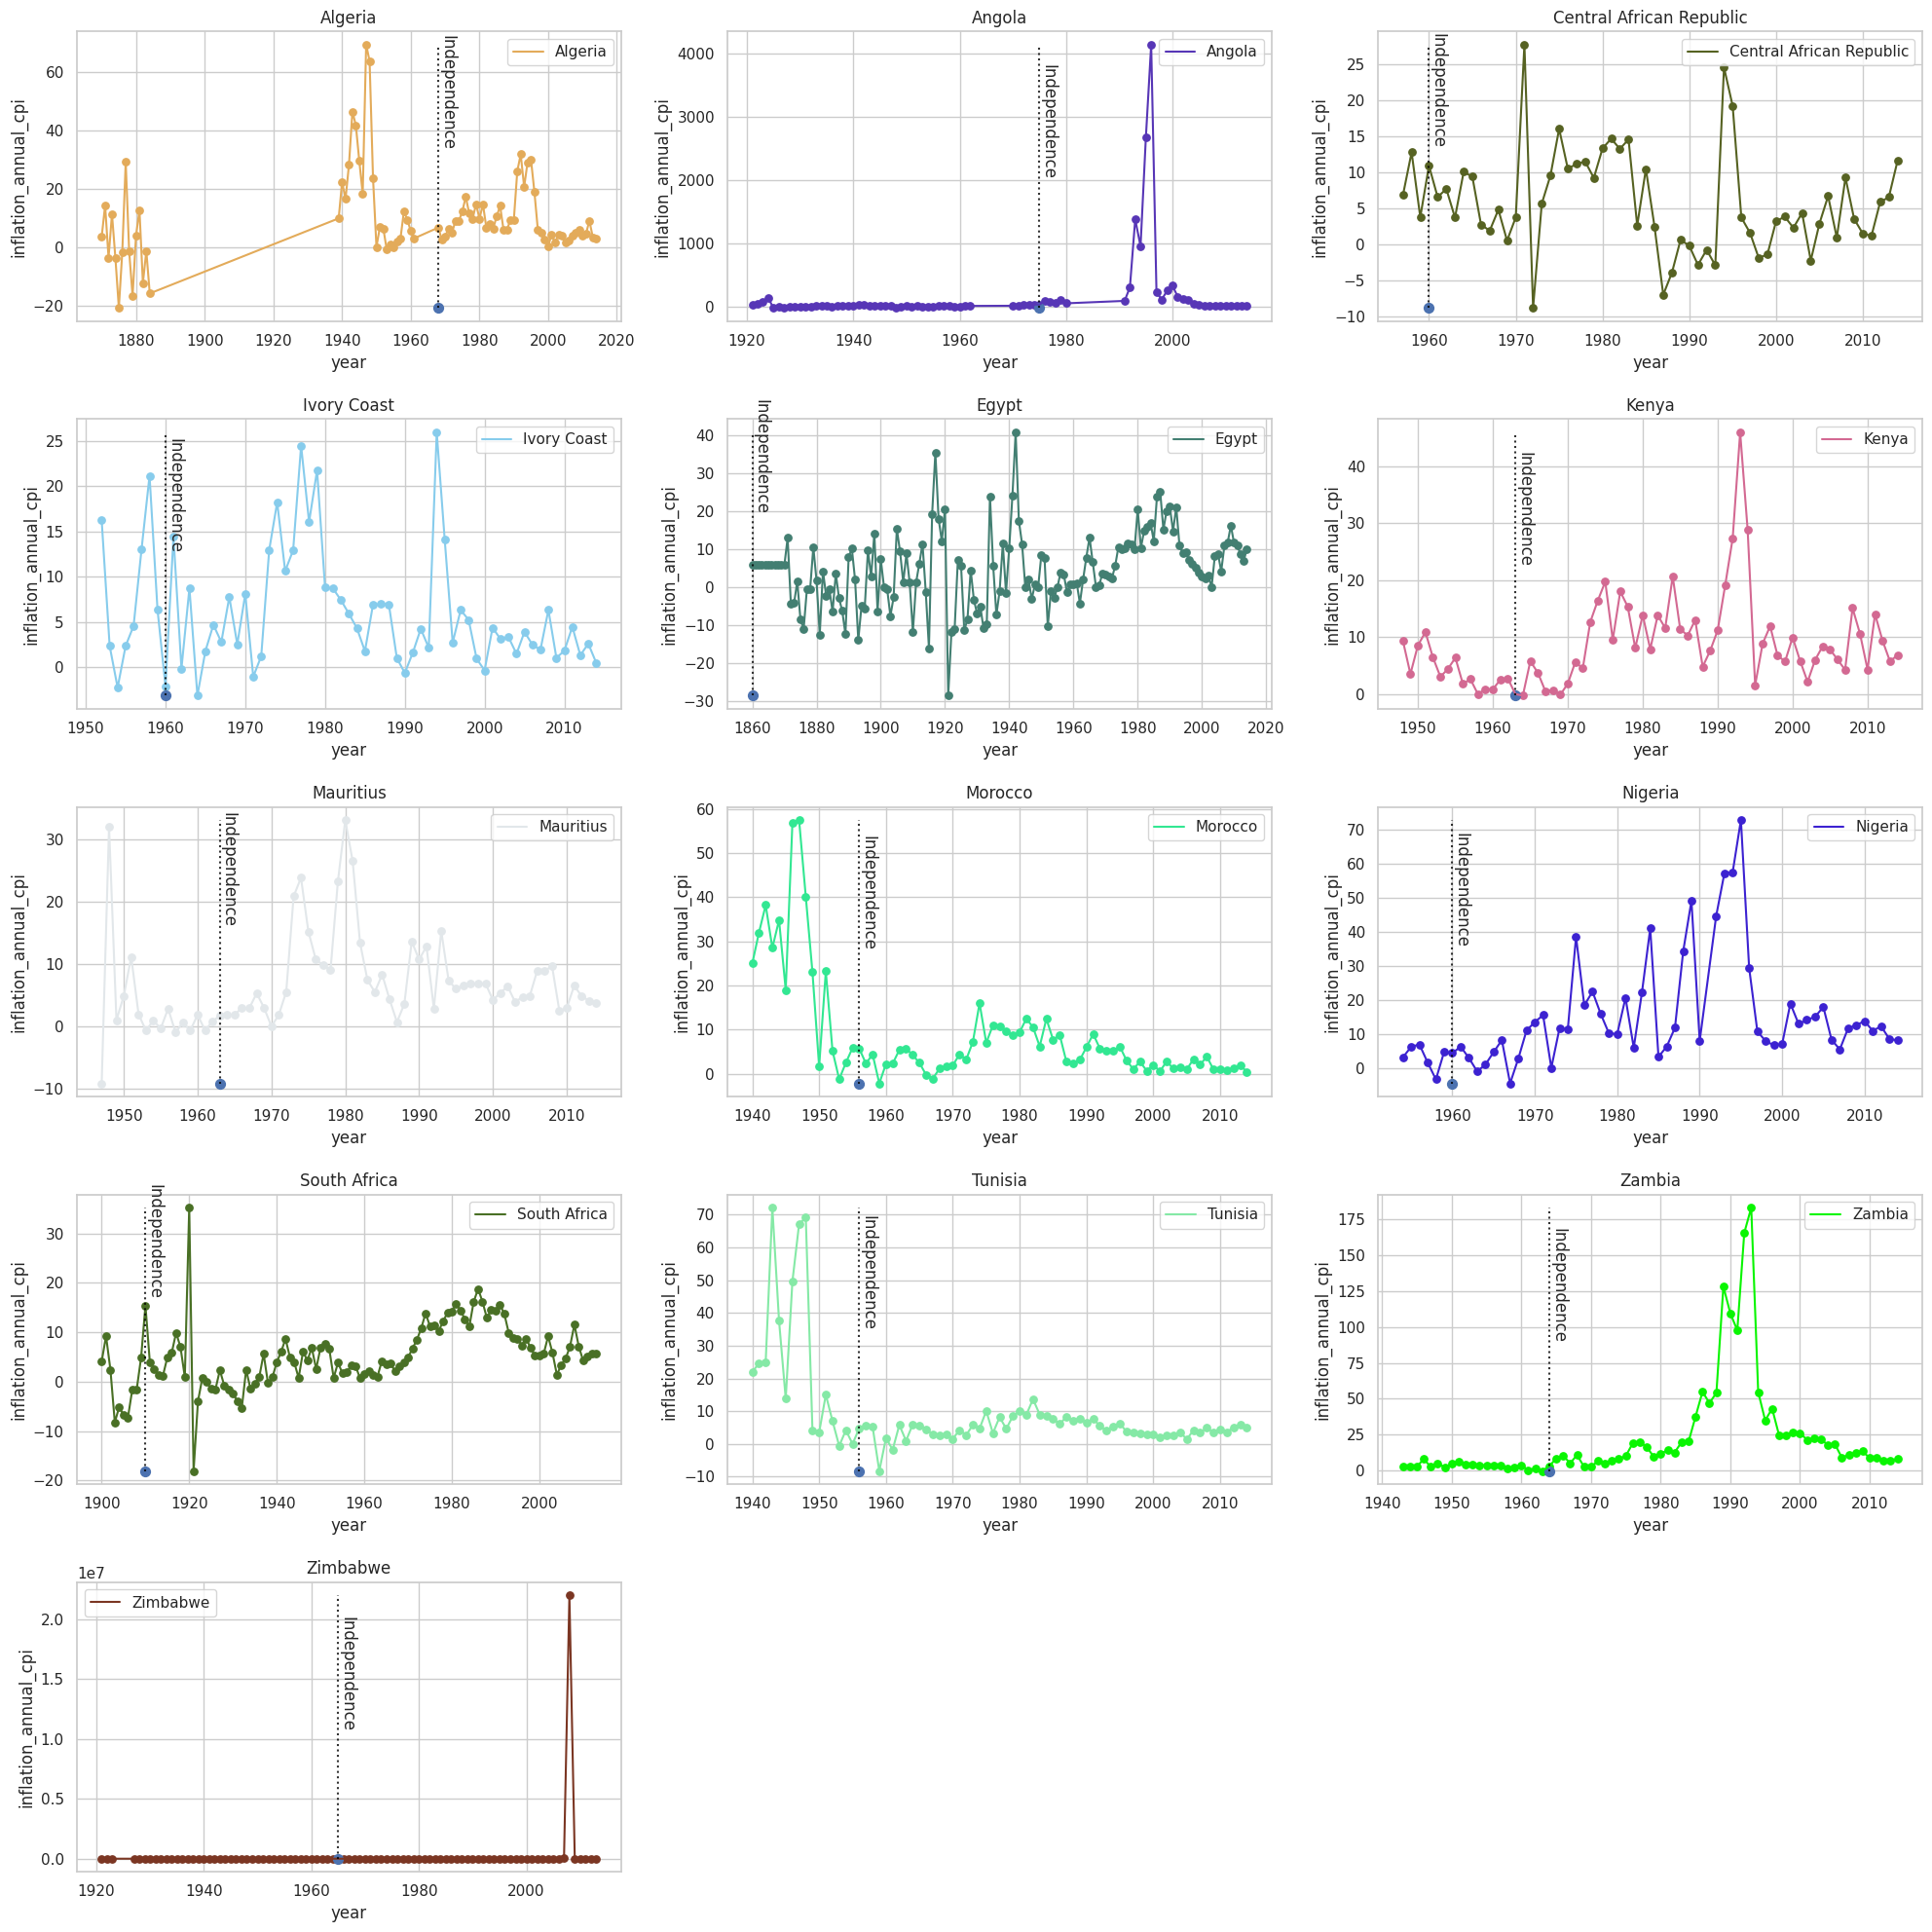

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import random

sns.set(style='whitegrid')
plt.figure(figsize=(20, 20))
count = 1
for country in unique_countries:
    plt.subplot(5, 3, count)
    count += 1
    col = "#" + ''.join([random.choice('0123456789ABCDEF') for j in range(6)])

    # CORRECTED: Use keyword arguments for lineplot
    sns.lineplot(
        x=data[data.country==country]['year'],
        y=data[data.country==country]['inflation_annual_cpi'],
        label=country,
        color=col
    )

    plt.scatter(data[data.country==country]['year'],
                data[data.country==country]['inflation_annual_cpi'],
                color=col,
                s=28)

    # Independence line
    independence_year = np.min(data[np.logical_and(data.country==country, data.independence==1)]['year'])
    min_inflation = np.min(data[data.country==country]['inflation_annual_cpi'])
    max_inflation = np.max(data[data.country==country]['inflation_annual_cpi'])

    plt.plot([independence_year, independence_year],
             [min_inflation, max_inflation],
             color='black',
             linestyle='dotted',
             alpha=0.8)

    plt.text(independence_year,
             max_inflation / 2,
             'Independence',
             rotation=-90)

    plt.scatter(x=independence_year,
                y=min_inflation,
                s=50)

    plt.title(country)

plt.tight_layout()
plt.show()


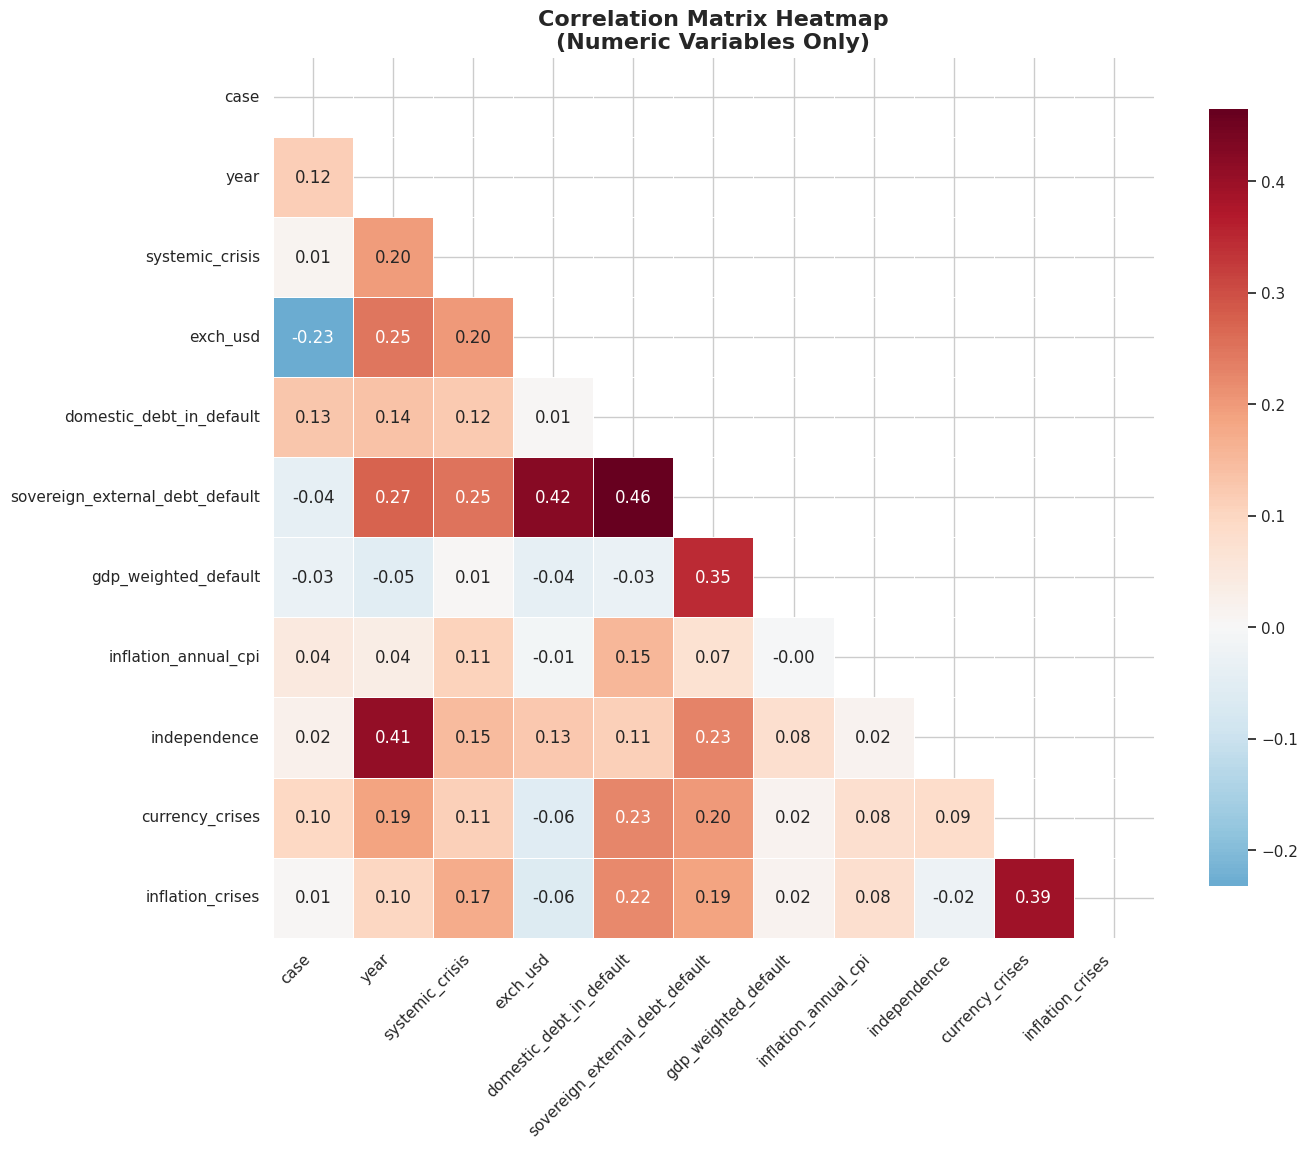

In [ ]:
# Correlation Plot - Only Numeric Columns
plt.figure(figsize=(14, 12))

# Select only numeric columns for correlation
numeric_data = data.select_dtypes(include=[np.number])
correlation_matrix = numeric_data.corr()

# Create mask for upper triangle (optional)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Enhanced heatmap
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    square=True,
    cbar_kws={'shrink': 0.8},
    linewidths=0.5
)

plt.title('Correlation Matrix Heatmap\n(Numeric Variables Only)', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
colors  = ("orange", "green", "red", "cyan", "brown", "grey", "blue", "indigo", "beige", "yellow","cadetblue","khaki")
plt.figure(figsize=(20,8))
plt.subplot(1,2,1)
plt.pie(currency_crises,labels='' colors=colors, autopct='%1.1f%%')
my_circle1=plt.Circle( (0,0), 0.7, color='white')
fig = plt.gcf() #gcf means get current figure
fig.suptitle("Winning Percentages by Alliances and Major Political Parties", fontsize=14) # Adding supertitle with pyplot import
ax = fig.gca() # gca means get current axis
ax.add_patch(my_circle1)

label = ax.annotate("2009", xy=(0, 0), fontsize=30, ha="center",va="center")

ax.axis('off')
ax.set_aspect('equal')
ax.autoscale_view()



#plt.figure(figsize=(20,10))
plt.subplot(1,2,2)
plt.pie(seats_won[2014], labels=seats_won['Alliance'], colors=colors,autopct='%1.1f%%')
my_circle2=plt.Circle( (0,0), 0.7, color='white')
fig = plt.gcf() #gcf means get current figure
ax = fig.gca() # gca means get current axis
ax.add_patch(my_circle2)

label = ax.annotate("2014", xy=(0, 0), fontsize=30, ha="center",va="center")

ax.axis('off')
ax.set_aspect('equal')
ax.autoscale_view()

plt.show();

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data = pd.read_csv("/content/african_crises.csv")

# Get the first 5 unique countries from the dataset
unique_countries = data.country.unique()
first_five_countries = unique_countries[:5]

# Filter the main DataFrame to include only these first 5 countries
data_filtered_for_pies = data[data['country'].isin(first_five_countries)]

# Select a few representative years for the "year wise split"
# These years were chosen to have good data coverage for multiple of the selected countries.
selected_years = [1960, 1970, 1980, 1990, 2000, 2010]

# Determine grid size for subplots
num_years = len(selected_years)
num_cols = 3
num_rows = (num_years + num_cols - 1) // num_cols

plt.figure(figsize=(num_cols * 5, num_rows * 5)) # Adjusted figure size for better display

plot_index = 1
for year in selected_years:
    # Filter data for the current year and the first 5 countries
    yearly_data = data_filtered_for_pies[data_filtered_for_pies['year'] == year].copy()

    # Drop rows where 'inflation_annual_cpi' is NaN, as these cannot be plotted
    yearly_data.dropna(subset=['inflation_annual_cpi'], inplace=True)

    # Check if there is data left for plotting after filtering
    if yearly_data.empty:
        # print(f"No valid inflation data for the first 5 countries in year {year}. Skipping plot.")
        continue

    # Pie charts are not suitable for negative values as they represent proportions of a whole.
    # To address this, we use the absolute value of the inflation.
    # This visualizes the *magnitude* of inflation contribution rather than the signed value.
    inflation_magnitudes = yearly_data['inflation_annual_cpi'].abs()

    # If the sum of absolute inflation is zero, a pie chart cannot be created
    if inflation_magnitudes.sum() == 0:
        # print(f"Sum of absolute inflation is zero for year {year}. Skipping plot.")
        continue

    plt.subplot(num_rows, num_cols, plot_index)

    # Generate the pie chart
    plt.pie(
        inflation_magnitudes,
        labels=yearly_data['country'],
        autopct='%1.1f%%',
        startangle=90
    )
    plt.title(f'Inflation Contribution (Absolute) - {year}')
    plt.axis('equal') # Ensures the pie chart is circular

    plot_index += 1

plt.tight_layout()
plt.show()

NameError: name 'data' is not defined